# Machine Learning Lab
## Experiment: 10 — Linear Support Vector Machine for Classification

### Objective
Train a linear-kernel Support Vector Machine on the Iris dataset, evaluate its performance, and visualize a two-feature decision boundary.

### Learning outcomes
- Prepare data for a machine-learning workflow.
- Train and evaluate the required model(s).
- Interpret the results rather than relying only on accuracy.

### Environment
Recommended: Python 3.10+ with `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.

## 1. Import libraries and load Iris
For a 2D decision-boundary plot, we use two features and two classes (setosa and versicolor). This keeps the plot interpretable. A separate model using all four features and all three classes is also evaluated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
iris = load_iris(as_frame=True)
display(iris.frame.head())
print("Classes:", list(iris.target_names))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## 2. Train a linear SVM using all four features
SVMs are sensitive to feature scale, so standardization is included in the pipeline.

Accuracy: 0.9736842105263158
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       1.00      0.92      0.96        13
   virginica       0.93      1.00      0.96        13

    accuracy                           0.97        38
   macro avg       0.98      0.97      0.97        38
weighted avg       0.98      0.97      0.97        38



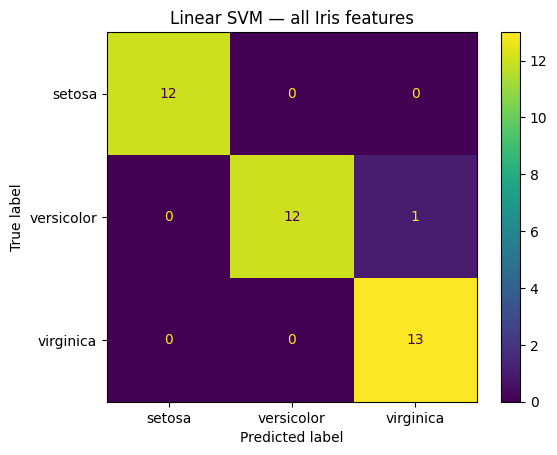

In [2]:
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

svm_all = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
svm_all.fit(X_train, y_train)
pred = svm_all.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=iris.target_names))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=iris.target_names)
plt.title("Linear SVM — all Iris features")
plt.show()

## 3. Fit a two-feature, two-class model for visualization
The features are sepal length and sepal width. Only Iris classes 0 and 1 are used for this 2D plot.

In [3]:
feature_names = ["sepal length (cm)", "sepal width (cm)"]
mask = iris.target.isin([0, 1])
X2 = iris.data.loc[mask, feature_names].to_numpy()
y2 = iris.target.loc[mask].to_numpy()

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.25, random_state=RANDOM_STATE, stratify=y2
)
svm_2d = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
svm_2d.fit(X2_train, y2_train)
print("Two-class, two-feature test accuracy:", accuracy_score(y2_test, svm_2d.predict(X2_test)))

Two-class, two-feature test accuracy: 0.96
 0.96


## 4. Plot the decision boundary
The shaded regions show the model's predicted class over a grid. The dots show the observations.

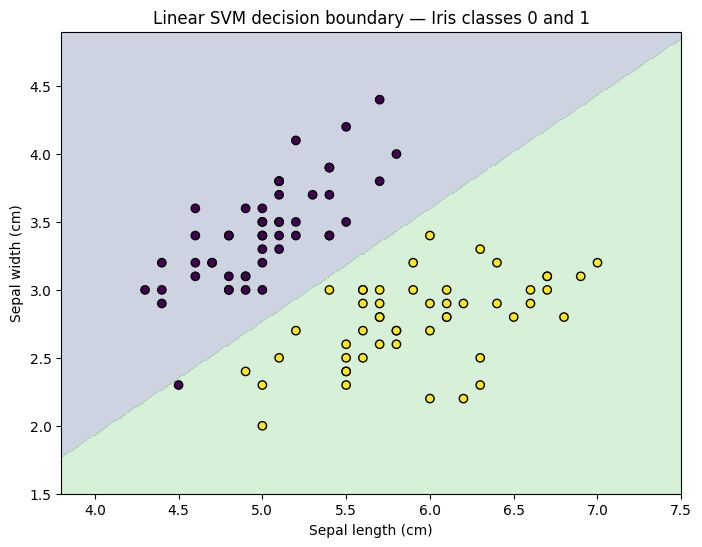

In [4]:
x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = svm_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5])
plt.scatter(X2[:, 0], X2[:, 1], c=y2, edgecolor="k", cmap="viridis")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Linear SVM decision boundary — Iris classes 0 and 1")
plt.show()

## 5. Conclusion
Explain the role of the separating hyperplane, why scaling matters, and why the 2D plot does not show the full four-feature model.